In [1]:
from google.colab import files
uploaded = files.upload()

Saving final_bn_data.csv to final_bn_data.csv
Saving cleanbn_fakenews.csv to cleanbn_fakenews.csv


In [2]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils import resample

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional


In [3]:

# Load datasets
df1 = pd.read_csv("final_bn_data.csv")
df2 = pd.read_csv("cleanbn_fakenews.csv")

# Clean & standardize
df1 = df1[['content', 'label']].rename(columns={'content': 'text'})
df2 = df2[['text', 'label']]
df1['text'] = df1['text'].fillna('')
df2['text'] = df2['text'].fillna('')

# Combine datasets
df = pd.concat([df1, df2], ignore_index=True).drop_duplicates().reset_index(drop=True)
df['label'] = df['label'].astype(int)
print("✅ Combined dataset shape:", df.shape)


✅ Combined dataset shape: (24763, 2)


In [4]:

def clean_bangla_text(text):
    text = re.sub(r'[^ঀ-৿\s]', '', text)  # keep only Bangla
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['clean_text'] = df['text'].apply(clean_bangla_text)


In [5]:

df_true = df[df['label'] == 0]
df_fake = df[df['label'] == 1]
df_true_upsampled = resample(df_true, replace=True, n_samples=len(df_fake), random_state=42)
df_bal = pd.concat([df_fake, df_true_upsampled]).sample(frac=1).reset_index(drop=True)


In [6]:

max_vocab = 20000
max_len = 250

tokenizer = Tokenizer(num_words=max_vocab, oov_token="<OOV>")
tokenizer.fit_on_texts(df_bal['clean_text'])

X = tokenizer.texts_to_sequences(df_bal['clean_text'])
X = pad_sequences(X, maxlen=max_len)
y = df_bal['label']


In [7]:

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

model = Sequential()
model.add(Embedding(input_dim=max_vocab, output_dim=128, input_length=max_len))
model.add(Bidirectional(LSTM(64)))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=5, batch_size=128)


Epoch 1/5
197/197 ━━━━━━━━━━━━━━━━━━━━ 208s 1s/step - accuracy: 0.6313 - loss: 0.6302 - val_accuracy: 0.7855 - val_loss: 0.4614
Epoch 2/5
197/197 ━━━━━━━━━━━━━━━━━━━━ 261s 1s/step - accuracy: 0.8626 - loss: 0.3384 - val_accuracy: 0.8270 - val_loss: 0.4017
Epoch 3/5
197/197 ━━━━━━━━━━━━━━━━━━━━ 257s 1s/step - accuracy: 0.9223 - loss: 0.2150 - val_accuracy: 0.8379 - val_loss: 0.4133
Epoch 4/5
197/197 ━━━━━━━━━━━━━━━━━━━━ 211s 1s/step - accuracy: 0.9487 - loss: 0.1451 - val_accuracy: 0.8445 - val_loss: 0.4489
Epoch 5/5
197/197 ━━━━━━━━━━━━━━━━━━━━ 204s 1s/step - accuracy: 0.9628 - loss: 0.1064 - val_accuracy: 0.8413 - val_loss: 0.4602


197/197 ━━━━━━━━━━━━━━━━━━━━ 15s 75ms/step
              precision    recall  f1-score   support

           0       0.81      0.89      0.85      3122
           1       0.88      0.79      0.83      3166

    accuracy                           0.84      6288
   macro avg       0.85      0.84      0.84      6288
weighted avg       0.85      0.84      0.84      6288



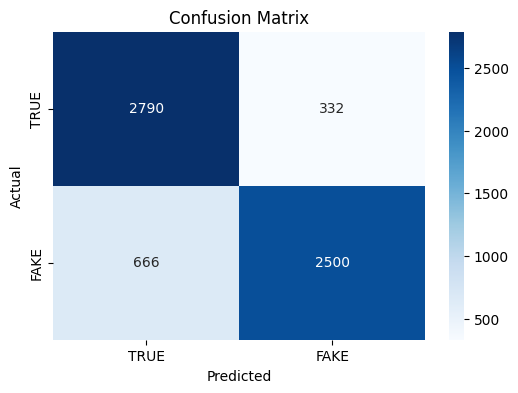

In [8]:

y_pred = model.predict(X_val)
y_pred_labels = (y_pred > 0.5).astype(int)

print(classification_report(y_val, y_pred_labels))

cm = confusion_matrix(y_val, y_pred_labels)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['TRUE','FAKE'], yticklabels=['TRUE','FAKE'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()


In [9]:

!pip install ipywidgets --quiet
import ipywidgets as widgets
from IPython.display import display, clear_output

def predict_news(text):
    text = clean_bangla_text(text)
    seq = tokenizer.texts_to_sequences([text])
    padded = pad_sequences(seq, maxlen=max_len)
    prob = model.predict(padded)[0][0]

    if prob < 0.4:
        print(f"🟢 এটি সত্য নিউজ (Confidence: {(1-prob)*100:.2f}%)")
    elif prob > 0.6:
        print(f"🔴 এটি মিথ্যা বা সন্দেহজনক নিউজ (Confidence: {prob*100:.2f}%)")
    else:
        print(f"🟡 নিশ্চিত হওয়া যাচ্ছে না (Score: {prob:.2f})")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 56.8 MB/s eta 0:00:00


In [10]:

text_input = widgets.Textarea(
    value='',
    placeholder='এখানে বাংলা নিউজ লিখুন...',
    description='নিউজ:',
    layout=widgets.Layout(width='100%', height='100px')
)

output_box = widgets.Output()
button = widgets.Button(description="Check News", button_style='success')

def on_button_click(b):
    with output_box:
        clear_output()
        text = text_input.value
        if not text.strip():
            print("⚠️ অনুগ্রহ করে একটি নিউজ লিখুন।")
        else:
            predict_news(text)

button.on_click(on_button_click)
display(text_input, button, output_box)


Textarea(value='', description='নিউজ:', layout=Layout(height='100px', width='100%'), placeholder='এখানে বাংলা …

Button(button_style='success', description='Check News', style=ButtonStyle())

Output()